In [1]:
import pyarrow.parquet as pq
import pandas as pd
import matplotlib.pyplot as plt
import awkward as ak
import numpy as np
import plotly.graph_objects as go
import torch

In [2]:
import sys
from pathlib import Path

from src.data.event_jets_data_loading import EventJetsL1TriggerDataset

In [6]:
# Initialize test dataset
dataset = EventJetsL1TriggerDataset(
    parquet_dirs="/run/media/francesco/STORAGE/data_class/minbias",
    max_jets=14,
    features=["L1T_JetPuppiAK4_PT",
            "L1T_JetPuppiAK4_Eta",
            "L1T_JetPuppiAK4_Phi",
        ],
    preprocessing=False
)

# Initialize test dataloader
dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=64,
    num_workers=0,
    pin_memory=True
)

In [7]:
pt = []
eta = []
phi = []
tot_events = 0
num_jets = []

for x, m in dataloader:
    pt.extend(x[:, :, 0][m])
    eta.extend(x[:, :, 1][m])
    phi.extend(x[:, :, 2][m])

    num_jets.extend(m.sum(axis=1))

    tot_events += x.shape[0]

In [8]:
print(f"Total events: {tot_events}")

Total events: 17565


In [12]:
# Initialize test dataset
dataset = EventJetsL1TriggerDataset(
    parquet_dirs="/run/media/francesco/STORAGE/data_class/ggHbb",
    max_jets=14,
    features=["L1T_JetPuppiAK4_PT",
            "L1T_JetPuppiAK4_Eta",
            "L1T_JetPuppiAK4_Phi",
        ],
    preprocessing=False
)

# Initialize test dataloader
dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=64,
    num_workers=0,
    pin_memory=True
)

In [13]:
pt = []
eta = []
phi = []
tot_events = 0
num_jets = []

for x, m in dataloader:
    pt.extend(x[:, :, 0][m])
    eta.extend(x[:, :, 1][m])
    phi.extend(x[:, :, 2][m])

    num_jets.extend(m.sum(axis=1))

    tot_events += x.shape[0]

In [14]:
print(f"Total events: {tot_events}")

Total events: 19483


Using device: cuda

================ METRICS ================
Accuracy    : 0.9394
Precision   : 0.9832
Recall      : 0.9002
Specificity : 0.9829
F1-score    : 0.9399
ROC-AUC     : 0.9806
PR-AUC      : 0.9858

Confusion matrix components:
TN = 3453
FP = 60
FN = 389
TP = 3508

Classification report:
              precision    recall  f1-score   support

     Minbias     0.8988    0.9829    0.9390      3513
       ggHbb     0.9832    0.9002    0.9399      3897

    accuracy                         0.9394      7410
   macro avg     0.9410    0.9416    0.9394      7410
weighted avg     0.9432    0.9394    0.9394      7410

Number of test events: 7410

Confusion matrix:
[[3453   60]
 [ 389 3508]]


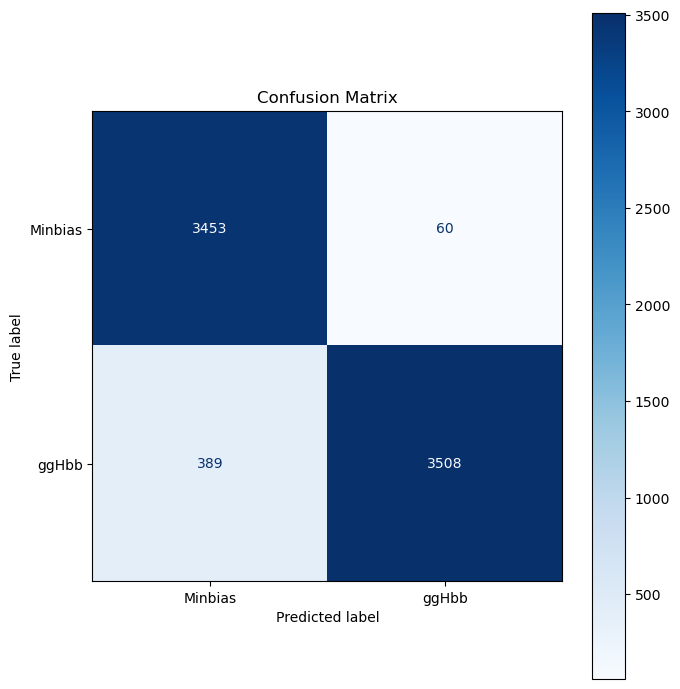


Normalized confusion matrix:
[[0.98292058 0.01707942]
 [0.09982037 0.90017963]]


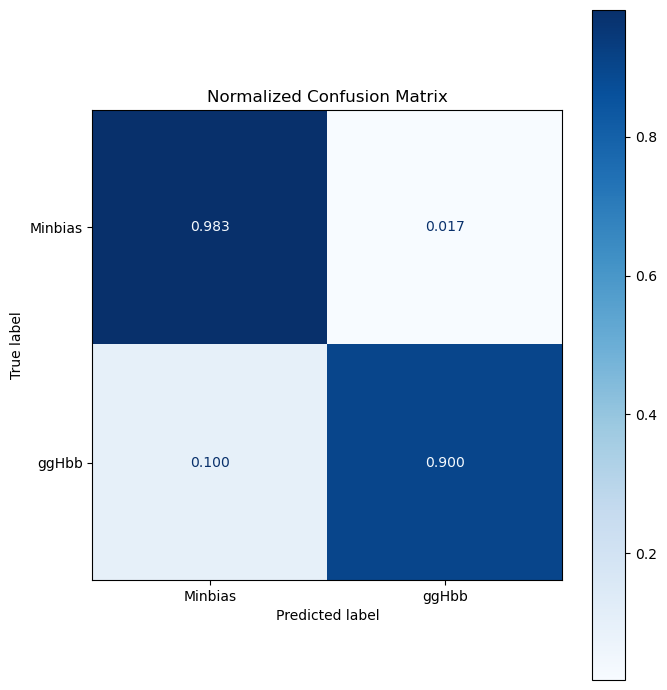


Done.


In [1]:
import os

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import lightning as L

from classifier.dataset import TokenDataModule
from classifier.classifier_model import EncoderClassificationModule 


# Checkpoint
CHECKPOINT_PATH = "checkpoints_classifier/class/v9-epoch=19-train_acc=0.9454-class.ckpt"

# Processes
CLASS_NAMES = [
    "Minbias",
    "ggHbb",
]

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {device}")


# ============================================================
# DATA MODULE
# ============================================================

data_module = TokenDataModule(
    tokens_path = "classifier/tokens/tokens.pt",
    masks_path = "classifier/tokens/masks.pt",
    labels_path = "classifier/tokens/labels.pt",
    cb_size = 1024,
    batch_size = 32,
    num_workers =0,
    test_size = 0.20,
    seed = 56
)

data_module.setup(stage="test")

test_loader = data_module.test_dataloader()


# ============================================================
# LOAD MODEL FROM CHECKPOINT
# ============================================================

model = EncoderClassificationModule.load_from_checkpoint(
    CHECKPOINT_PATH
)

model = model.to(device)
model.eval()


# ============================================================
# INFERENCE
# ============================================================

all_labels = []
all_predictions = []
all_probabilities = []


with torch.no_grad():

    for batch_idx, batch in enumerate(test_loader):

        x = batch['tokens']
        mask = batch['mask']
        labels = batch['label']

        x = x.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        logits = model(x, mask)

        # ----------------------------------------------------
        # Binary classification
        # ----------------------------------------------------

        if logits.ndim == 1:
            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).long()

        elif logits.shape[-1] == 1:
            probabilities = torch.sigmoid(logits.squeeze(-1))
            predictions = (probabilities >= 0.5).long()

        # ----------------------------------------------------
        # Multi-class classification
        # ----------------------------------------------------

        else:
            probabilities = torch.softmax(logits, dim=-1)
            predictions = torch.argmax(probabilities, dim=-1)

        all_labels.append(labels.detach().cpu())
        all_predictions.append(predictions.detach().cpu())
        all_probabilities.append(probabilities.detach().cpu())


# ============================================================
# CONCATENATE
# ============================================================

y_true = torch.cat(all_labels).numpy()
y_pred = torch.cat(all_predictions).numpy()

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
)

# ============================================================
# CLASSIFICATION METRICS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0,
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0,
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0,
)

# ============================================================
# CONFUSION MATRIX COMPONENTS
# ============================================================

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

# ============================================================
# ROC-AUC AND PR-AUC
# ============================================================

# For binary classification, use the probability of class 1
y_prob = torch.cat(all_probabilities).numpy()

if y_prob.ndim > 1:
    y_prob = y_prob[:, 1]

roc_auc = roc_auc_score(
    y_true,
    y_prob,
)

pr_auc = average_precision_score(
    y_true,
    y_prob,
)

# ============================================================
# PRINT METRICS
# ============================================================

print("\n================ METRICS ================")

print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}")
print(f"PR-AUC      : {pr_auc:.4f}")

print("\nConfusion matrix components:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

print(f"Number of test events: {len(y_true)}")


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
)

print("\nConfusion matrix:")
print(cm)


# ============================================================
# RAW CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True,
)

ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

plt.tight_layout()
plt.show()


# ============================================================
# NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    normalize="true",
)

print("\nNormalized confusion matrix:")
print(cm_normalized)


fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=CLASS_NAMES,
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".3f",
    colorbar=True,
)

ax.set_title("Normalized Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

print("\nDone.")

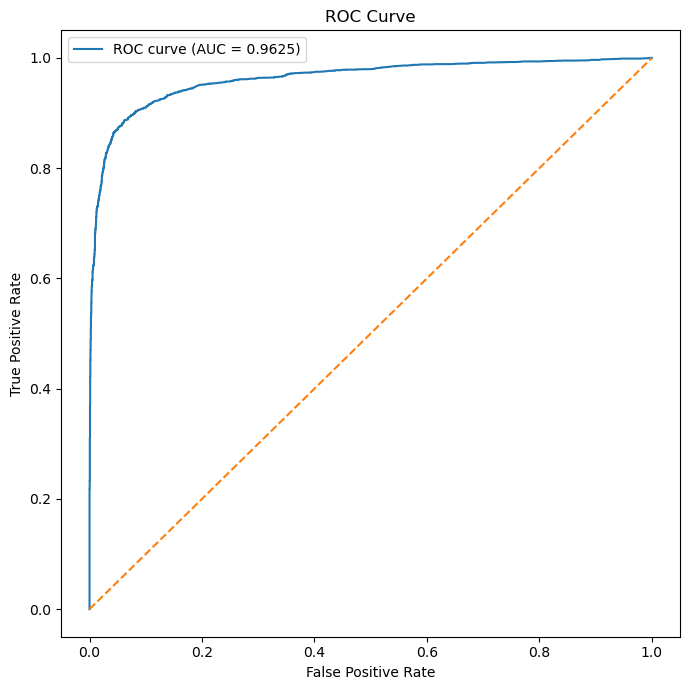

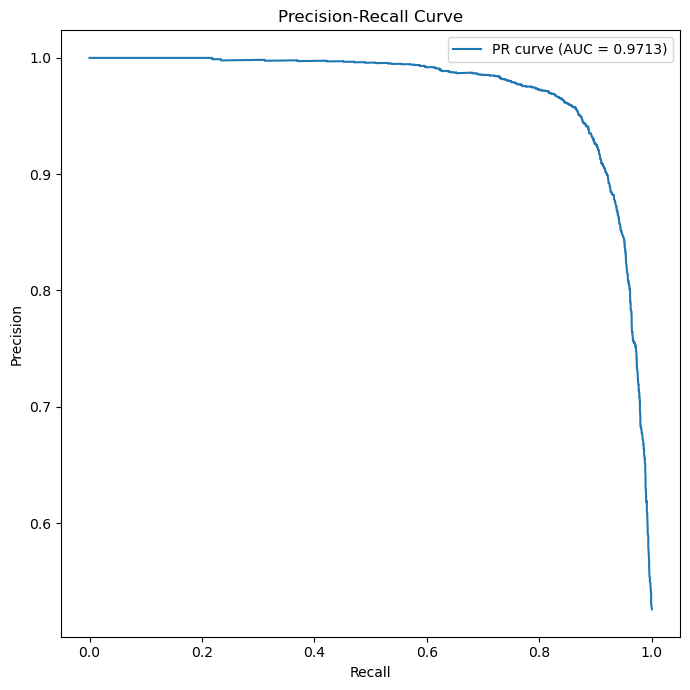

In [23]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
)

# ============================================================
# ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc_curve = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    fpr,
    tpr,
    label=f"ROC curve (AUC = {roc_auc_curve:.4f})",
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, _ = precision_recall_curve(
    y_true,
    y_prob,
)

pr_auc_curve = auc(
    recall_curve,
    precision_curve,
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    recall_curve,
    precision_curve,
    label=f"PR curve (AUC = {pr_auc_curve:.4f})",
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve")
ax.legend()

plt.tight_layout()
plt.show()

# Baseline


Using device: cuda

================ METRICS ================
Accuracy    : 0.9231
Precision   : 0.9291
Recall      : 0.9243
Specificity : 0.9217
F1-score    : 0.9267
ROC-AUC     : 0.9735
PR-AUC      : 0.9806

Confusion matrix components:
TN = 3238
FP = 275
FN = 295
TP = 3602

Classification report:
              precision    recall  f1-score   support

     Minbias     0.9165    0.9217    0.9191      3513
       ggHbb     0.9291    0.9243    0.9267      3897

    accuracy                         0.9231      7410
   macro avg     0.9228    0.9230    0.9229      7410
weighted avg     0.9231    0.9231    0.9231      7410

Number of test events: 7410

Confusion matrix:
[[3238  275]
 [ 295 3602]]


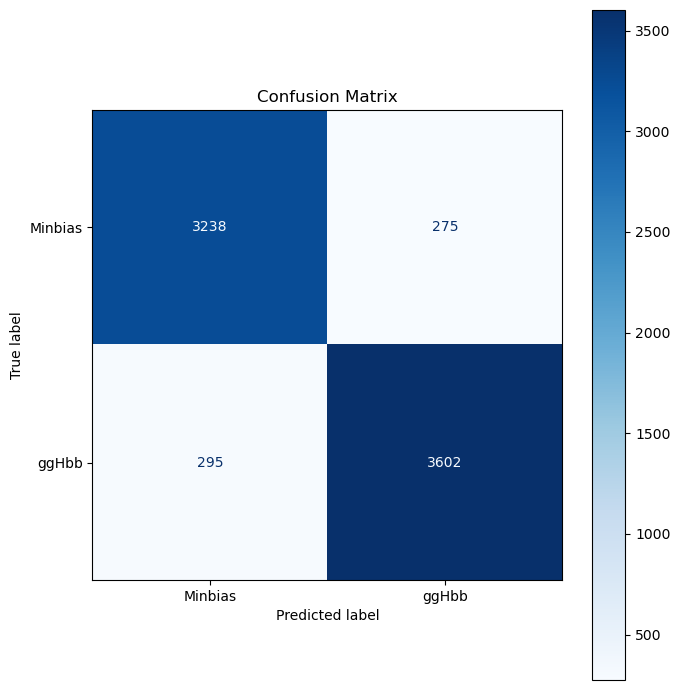


Normalized confusion matrix:
[[0.92171933 0.07828067]
 [0.07569926 0.92430074]]


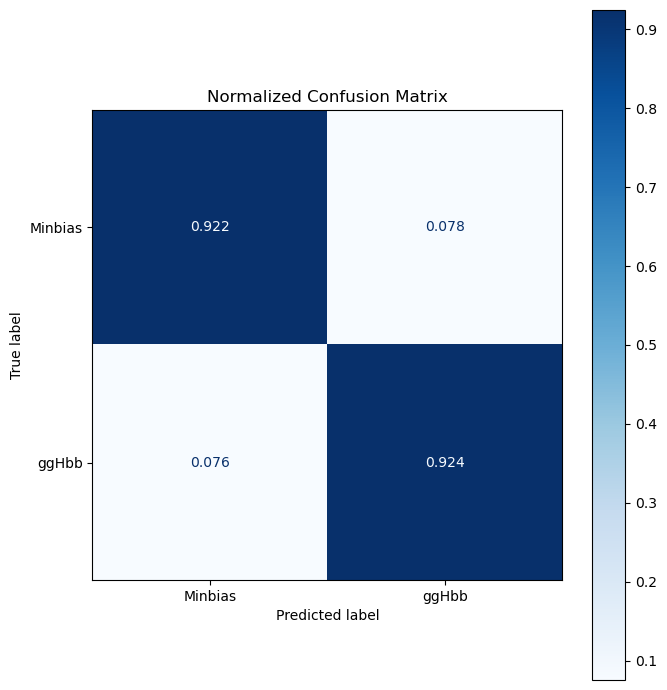


Done.


In [ ]:
import os

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import lightning as L

from classifier_baseline.dataset_base import OriginalDataModule
from classifier_baseline.model_baseline import EncoderClassificationModule 


# Checkpoint
CHECKPOINT_PATH = "checkpoints_base_classifier/base_class/v21-epoch=09-train_acc=0.9211-base_class.ckpt"

# Processes
CLASS_NAMES = [
    "Minbias",
    "ggHbb",
]

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {device}")


# ============================================================
# DATA MODULE
# ============================================================

data_module = OriginalDataModule(
    data_path = "classifier_baseline/data/data.pt",
    masks_path = "classifier_baseline/data/masks.pt",
    labels_path = "classifier_baseline/data/labels.pt",
    batch_size = 32,
    num_workers =0,
    test_size = 0.20,
    seed = 15
)

data_module.setup(stage="test")

test_loader = data_module.test_dataloader()


# ============================================================
# LOAD MODEL FROM CHECKPOINT
# ============================================================

model = EncoderClassificationModule.load_from_checkpoint(
    CHECKPOINT_PATH
)

model = model.to(device)
model.eval()


# ============================================================
# INFERENCE
# ============================================================

all_labels = []
all_predictions = []
all_probabilities = []


with torch.no_grad():

    for batch_idx, batch in enumerate(test_loader):

        x = batch['data']
        mask = batch['mask']
        labels = batch['label']

        x = x.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        logits = model(x, mask)

        # ----------------------------------------------------
        # Binary classification
        # ----------------------------------------------------

        if logits.ndim == 1:
            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).long()

        elif logits.shape[-1] == 1:
            probabilities = torch.sigmoid(logits.squeeze(-1))
            predictions = (probabilities >= 0.5).long()

        # ----------------------------------------------------
        # Multi-class classification
        # ----------------------------------------------------

        else:
            probabilities = torch.softmax(logits, dim=-1)
            predictions = torch.argmax(probabilities, dim=-1)

        all_labels.append(labels.detach().cpu())
        all_predictions.append(predictions.detach().cpu())
        all_probabilities.append(probabilities.detach().cpu())


# ============================================================
# CONCATENATE
# ============================================================

y_true = torch.cat(all_labels).numpy()
y_pred = torch.cat(all_predictions).numpy()

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
)

# ============================================================
# CLASSIFICATION METRICS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0,
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0,
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0,
)

# ============================================================
# CONFUSION MATRIX COMPONENTS
# ============================================================

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

# ============================================================
# ROC-AUC AND PR-AUC
# ============================================================

# For binary classification, use the probability of class 1
y_prob = torch.cat(all_probabilities).numpy()

if y_prob.ndim > 1:
    y_prob = y_prob[:, 1]

roc_auc = roc_auc_score(
    y_true,
    y_prob,
)

pr_auc = average_precision_score(
    y_true,
    y_prob,
)

# ============================================================
# PRINT METRICS
# ============================================================

print("\n================ METRICS ================")

print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}")
print(f"PR-AUC      : {pr_auc:.4f}")

print("\nConfusion matrix components:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

print(f"Number of test events: {len(y_true)}")


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
)

print("\nConfusion matrix:")
print(cm)


# ============================================================
# RAW CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True,
)

ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

plt.tight_layout()
plt.show()


# ============================================================
# NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    normalize="true",
)

print("\nNormalized confusion matrix:")
print(cm_normalized)


fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=CLASS_NAMES,
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".3f",
    colorbar=True,
)

ax.set_title("Normalized Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

print("\nDone.")

/tmp/ipykernel_43058/979666503.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


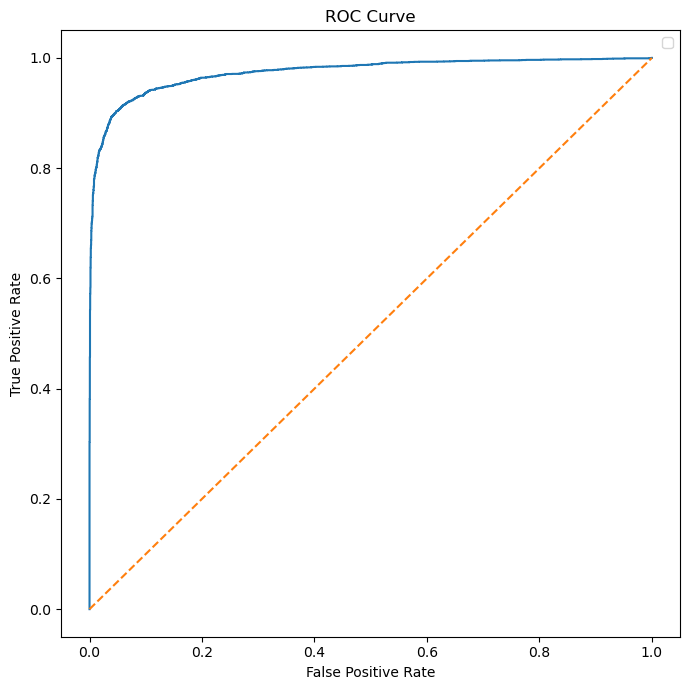

/tmp/ipykernel_43058/979666503.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


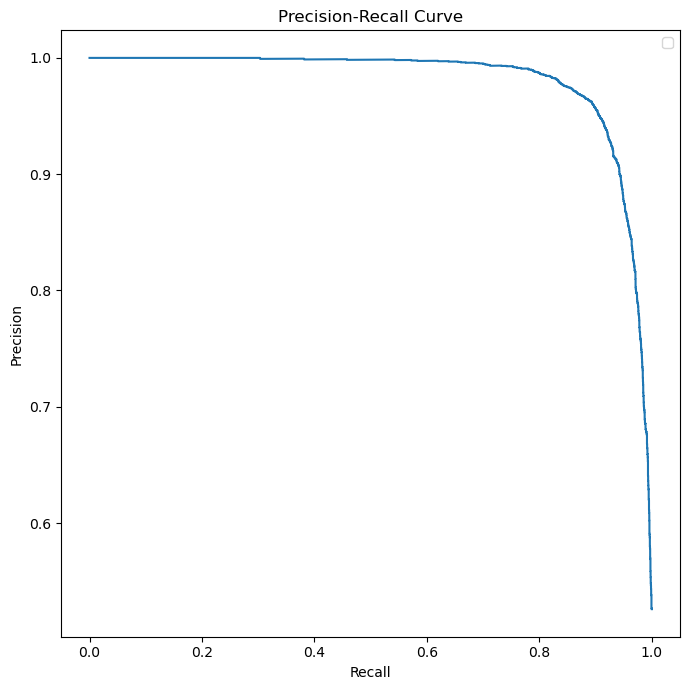

In [4]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
)

# ============================================================
# ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc_curve = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    fpr,
    tpr,
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, _ = precision_recall_curve(
    y_true,
    y_prob,
)

pr_auc_curve = auc(
    recall_curve,
    precision_curve,
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    recall_curve,
    precision_curve,
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
acc_runs = np.array([0.9248, 0.9243, 0.9231])
prec_runs = np.array([0.9434, 0.9585, 0.9291])
recall_runs = np.array([0.9117, 0.8948, 0.9243])
spec_runs = np.array([0.9394, 0.9570, 0.9217])
f1_runs = np.array([0.9273, 0.9255, 0.9267])
roc_runs = np.array([0.9726, 0.9721, 0.9735])
pr_runs = np.array([0.9791, 0.9789, 0.9806])


In [7]:
l = [acc_runs, prec_runs, recall_runs, spec_runs, f1_runs, roc_runs, pr_runs]

for metric in l:
    print(np.mean(metric))
    print(np.std(metric))
    print("------")
    

0.9240666666666666
0.0007133644853010615
------
0.9436666666666667
0.012003980821192417
------
0.9102666666666667
0.012085896279916046
------
0.9393666666666666
0.014411183928540438
------
0.9265
0.0007483314773547949
------
0.9727333333333333
0.0005792715732327845
------
0.9795333333333334
0.0007586537784494233
------
